# InsightX: Pharmaceutical Drug Sales Demand Prediction

**Goal:** predict how many units of a drug a pharmacy will sell on a given day, so that stock can be planned in advance (avoiding both stock-outs and over-stocking).

This notebook covers the complete workflow:

| Step | What we do |
|------|-----------|
| 1 | Load the daily sales dataset and check its quality |
| 2 | Exploratory data analysis (EDA) |
| 3 | Feature engineering, preprocessing and a time-based train / test split |
| 4 | Train **Linear Regression** and **Random Forest** models (plus a naive baseline) |
| 5 | Evaluate and compare the models |
| 6 | Find out which factors drive demand |
| 7 | Build a demand-planning view (predicted demand by category and month) |
| 8 | Save the trained models (`.pkl`) and predict for new scenarios |

> **Note on the data:** `data.csv` is a **synthetic** daily sales dataset (365 days, 4 drugs, 4 categories). It uses the same columns as the original notebook, but `Quantity_Sold` now follows realistic patterns (seasonality, weekends, price effect) plus noise. With purely random quantities, no model can learn anything (R-squared stays at zero), which is why the patterns were added. If `data.csv` is missing, the notebook regenerates it (Section 1).

## 0. Setup

In [1]:
# Google Colab only: uncomment to fetch the repo so that data.csv is available
# !git clone https://github.com/<your-username>/<your-repo-name>.git
# %cd <your-repo-name>

In [2]:
import os
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 40)

RANDOM_STATE = 42
BLUE, RED, AMBER, GREEN, SLATE = '#2563eb', '#ef4444', '#f59e0b', '#22c55e', '#64748b'

print('scikit-learn version:', sklearn.__version__)

scikit-learn version: 1.8.0


## 1. Dataset loading and initial exploration

| Column | Description |
|--------|-------------|
| `Date` | Day of sale (daily, 1 Jan 2023 to 31 Dec 2023) |
| `Drug_ID` | Drug sold (`Drug_A` ... `Drug_D`) |
| `Category` | Therapeutic category: Antibiotics, Analgesics, Antivirals, Cardiology |
| `Quantity_Sold` | **Target:** number of units sold that day |
| `Unit_Price` | Selling price per unit |

The cell below defines the generator that creates `data.csv`. It only runs if the file does not exist yet.

In [3]:
def generate_sales_data(seed=42):
    """Synthetic daily pharmacy sales (same columns as the original notebook).

    Quantity_Sold now follows realistic business patterns plus random noise:
    drug and category popularity, winter peak for antibiotics / antivirals,
    lower weekend sales, and lower demand when the unit price is high.
    """
    np.random.seed(seed)
    dates = pd.date_range(start="2023-01-01", periods=365, freq='D')
    categories = ['Antibiotics', 'Analgesics', 'Antivirals', 'Cardiology']
    drugs = ['Drug_A', 'Drug_B', 'Drug_C', 'Drug_D']

    drug_id = np.random.choice(drugs, 365)
    category = np.random.choice(categories, 365)
    unit_price = np.random.uniform(10.0, 150.0, 365).round(2)

    drug_effect = pd.Series(drug_id).map({'Drug_A': 6, 'Drug_B': 0, 'Drug_C': -5, 'Drug_D': 3}).values
    cat_effect = pd.Series(category).map({'Antibiotics': 4, 'Analgesics': 8, 'Antivirals': -2, 'Cardiology': 0}).values
    month = dates.month.values
    winter_peak = np.cos(2 * np.pi * (month - 1) / 12)                      # +1 in January, -1 in July
    season = np.where(np.isin(category, ['Antibiotics', 'Antivirals']), 14 * winter_peak, 0)
    weekend = (dates.dayofweek.values >= 5).astype(int)

    quantity = (42 + drug_effect + cat_effect + season - 7 * weekend
                - 0.18 * (unit_price - 80) + np.random.normal(0, 6, 365))
    quantity = np.clip(np.round(quantity), 5, 150)

    return pd.DataFrame({'Date': dates, 'Drug_ID': drug_id, 'Category': category,
                         'Quantity_Sold': quantity.astype(float), 'Unit_Price': unit_price})


DATA_PATH = 'data.csv'

if not os.path.exists(DATA_PATH):
    generate_sales_data().to_csv(DATA_PATH, index=False)
    print('data.csv not found -> generated a fresh synthetic dataset.')

df = pd.read_csv(DATA_PATH, parse_dates=['Date'])
print('Dataset Shape:', df.shape)
df.head()

data.csv not found -> generated a fresh synthetic dataset.
Dataset Shape: (365, 5)


,Date,Drug_ID,Category,Quantity_Sold,Unit_Price
0,2023-01-01,Drug_C,Antivirals,47.0,64.05
1,2023-01-02,Drug_D,Analgesics,39.0,144.57
2,2023-01-03,Drug_A,Analgesics,48.0,136.75
3,2023-01-04,Drug_C,Antivirals,69.0,37.41
4,2023-01-05,Drug_C,Antivirals,65.0,19.71


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           365 non-null    datetime64[us]
 1   Drug_ID        365 non-null    str           
 2   Category       365 non-null    str           
 3   Quantity_Sold  365 non-null    float64       
 4   Unit_Price     365 non-null    float64       
dtypes: datetime64[us](1), float64(2), str(2)
memory usage: 14.4 KB


In [5]:
print('Missing values :', int(df.isna().sum().sum()))
print('Duplicate rows :', int(df.duplicated().sum()))
print('Date range     :', df['Date'].min().date(), 'to', df['Date'].max().date(), f'({df["Date"].nunique()} unique days)')
df.describe().T.round(2)

Missing values : 0
Duplicate rows : 0
Date range     : 2023-01-01 to 2023-12-31 (365 unique days)


,count,mean,min,25%,50%,75%,max,std
Date,365,2023-07-02 00:00:00,2023-01-01 00:00:00,2023-04-02 00:00:00,2023-07-02 00:00:00,2023-10-01 00:00:00,2023-12-31 00:00:00,NaN
Quantity_Sold,365.0,43.991781,5.0,34.0,45.0,54.0,78.0,13.610453
Unit_Price,365.0,79.249863,11.52,39.81,78.9,116.61,149.96,42.089334


## 1.1 Exploratory Data Analysis (EDA)

Let's look at the distributions, patterns over time and relationships between the features before building models.

### Distribution of the target and of the price

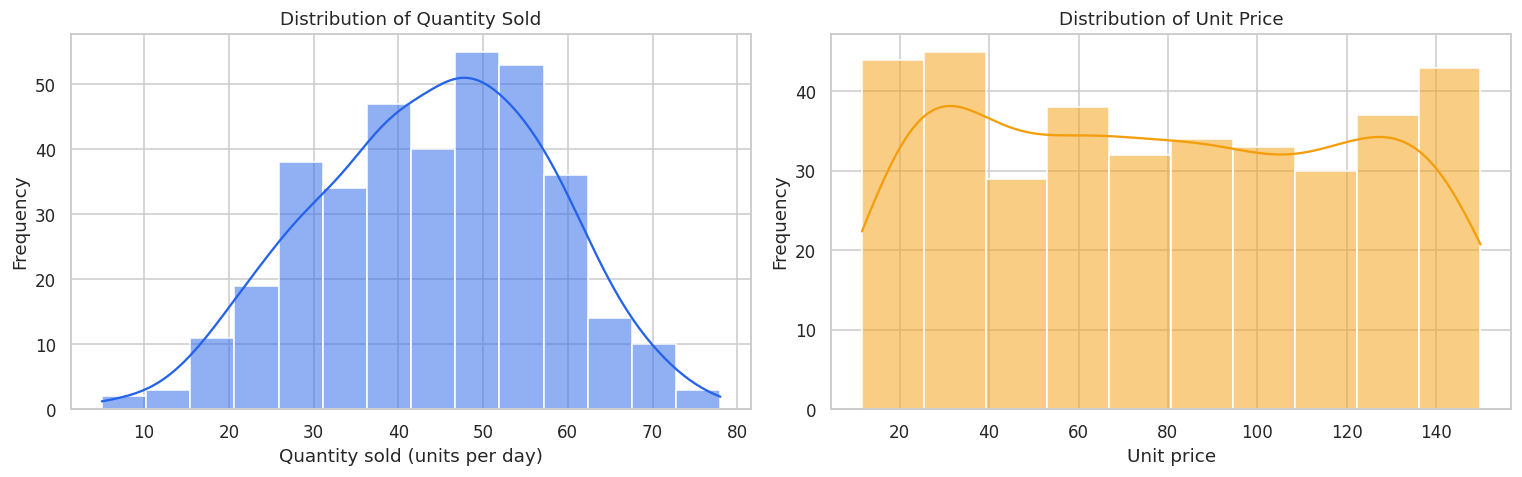

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(df['Quantity_Sold'], kde=True, ax=axes[0], color=BLUE)
axes[0].set_title('Distribution of Quantity Sold')
axes[0].set_xlabel('Quantity sold (units per day)')
axes[0].set_ylabel('Frequency')

sns.histplot(df['Unit_Price'], kde=True, ax=axes[1], color=AMBER)
axes[1].set_title('Distribution of Unit Price')
axes[1].set_xlabel('Unit price')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Average quantity sold by category and by drug

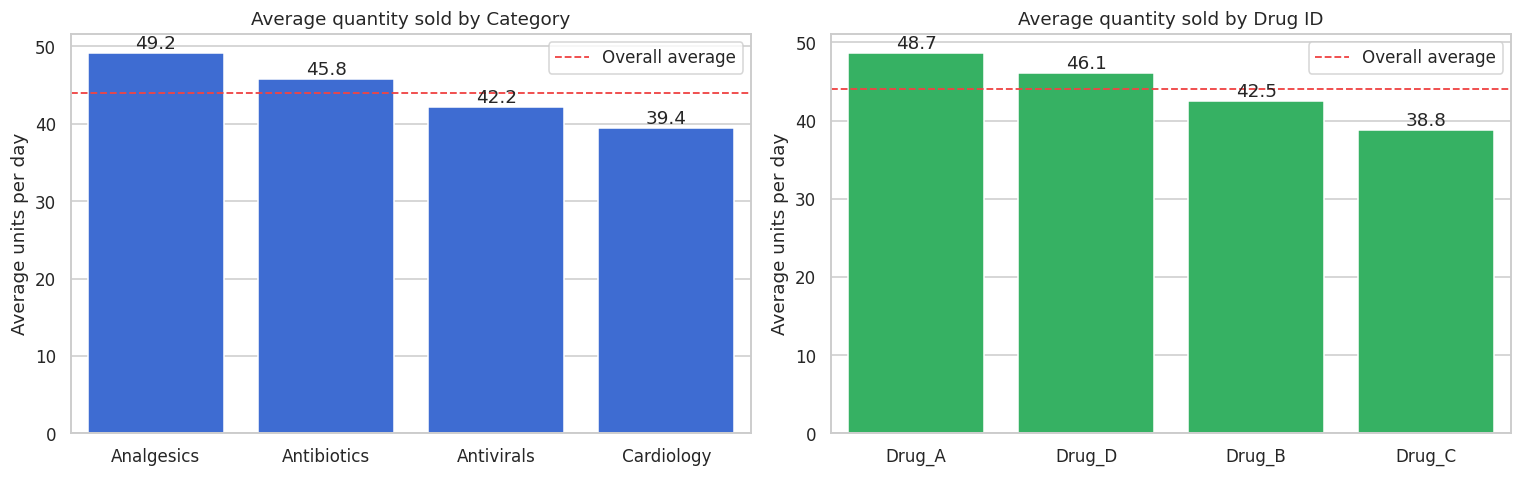

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for ax, col, color in zip(axes, ['Category', 'Drug_ID'], [BLUE, GREEN]):
    avg = df.groupby(col)['Quantity_Sold'].mean().sort_values(ascending=False)
    sns.barplot(x=avg.index, y=avg.values, ax=ax, color=color)
    for i, v in enumerate(avg.values):
        ax.text(i, v + 0.6, f'{v:.1f}', ha='center')
    ax.axhline(df['Quantity_Sold'].mean(), color=RED, ls='--', lw=1.2, label='Overall average')
    ax.set_title(f'Average quantity sold by {col.replace("_", " ")}')
    ax.set_xlabel('')
    ax.set_ylabel('Average units per day')
    ax.legend()

plt.tight_layout()
plt.show()

### Seasonality: monthly pattern by category

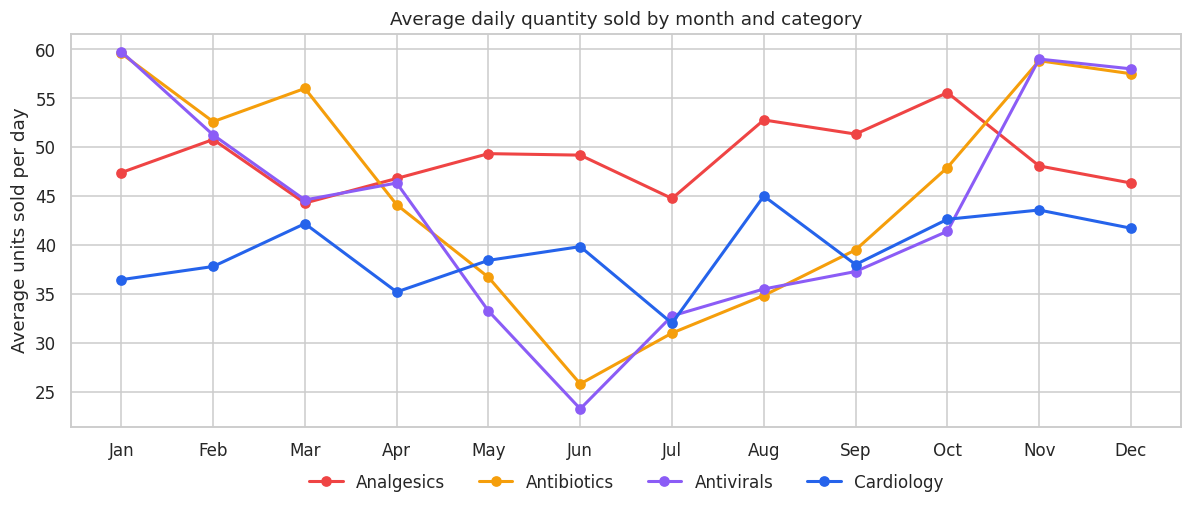

In [8]:
monthly = (df.assign(Month=df['Date'].dt.month)
           .groupby(['Month', 'Category'])['Quantity_Sold'].mean().unstack())

fig, ax = plt.subplots(figsize=(11, 4.8))
for col, color in zip(monthly.columns, [RED, AMBER, '#8b5cf6', BLUE]):
    ax.plot(monthly.index, monthly[col], marker='o', lw=2, label=col, color=color)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax.set_ylabel('Average units sold per day')
ax.set_title('Average daily quantity sold by month and category')
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.tight_layout()
plt.show()

Antibiotics and Antivirals are clearly **seasonal** (highest in winter, lowest in mid-year), while Analgesics and Cardiology show no clear seasonal pattern (their month-to-month changes look like random fluctuation).

### Weekday effect and price effect

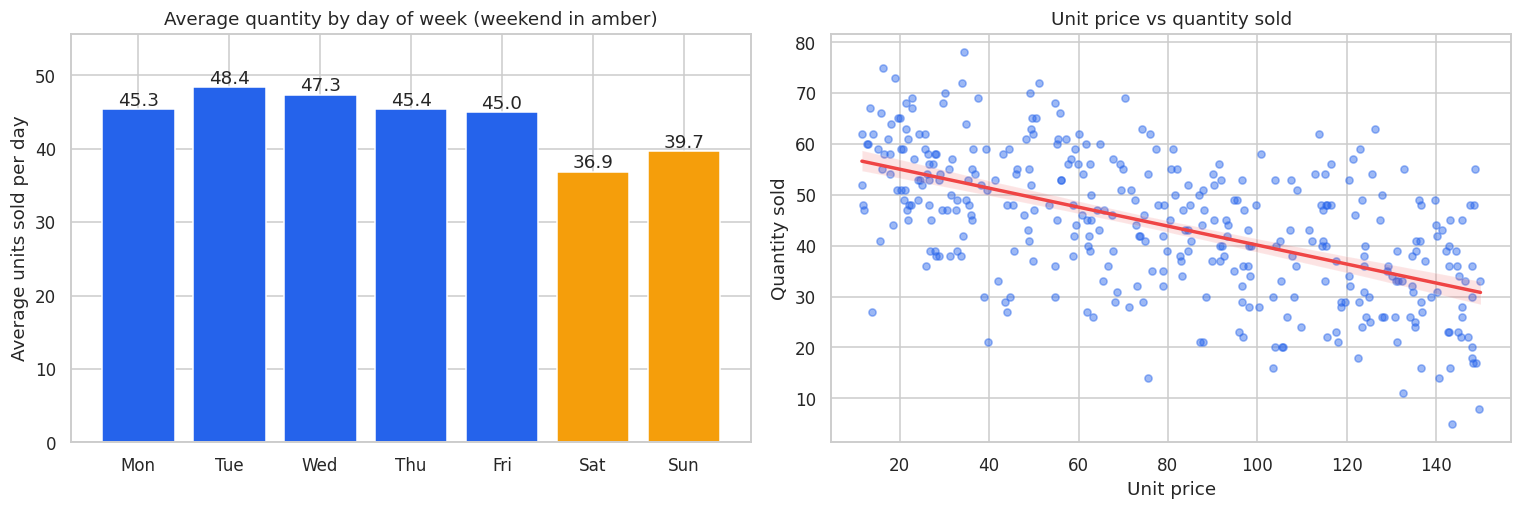

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Weekday pattern
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
dow = df.groupby(df['Date'].dt.dayofweek)['Quantity_Sold'].mean()
axes[0].bar(days, dow.values, color=[BLUE] * 5 + [AMBER] * 2)
for i, v in enumerate(dow.values):
    axes[0].text(i, v + 0.5, f'{v:.1f}', ha='center')
axes[0].set_ylim(0, dow.max() * 1.15)
axes[0].set_ylabel('Average units sold per day')
axes[0].set_title('Average quantity by day of week (weekend in amber)')

# Price vs quantity
sns.regplot(data=df, x='Unit_Price', y='Quantity_Sold', ax=axes[1],
            scatter_kws={'alpha': 0.45, 's': 22, 'color': BLUE}, line_kws={'color': RED})
axes[1].set_title('Unit price vs quantity sold')
axes[1].set_xlabel('Unit price')
axes[1].set_ylabel('Quantity sold')

plt.tight_layout()
plt.show()

Weekends sell less, and demand falls as the unit price rises (negative slope).

### Revenue by category

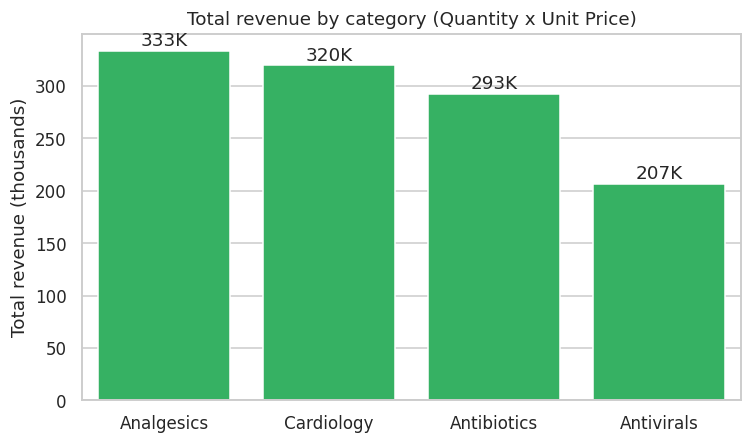

In [10]:
revenue = (df.assign(Revenue=df['Quantity_Sold'] * df['Unit_Price'])
           .groupby('Category')['Revenue'].sum().sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(7, 4.2))
sns.barplot(x=revenue.index, y=revenue.values / 1000, color=GREEN, ax=ax)
for i, v in enumerate(revenue.values / 1000):
    ax.text(i, v + 5, f'{v:,.0f}K', ha='center')
ax.set_ylabel('Total revenue (thousands)')
ax.set_xlabel('')
ax.set_title('Total revenue by category (Quantity x Unit Price)')
plt.tight_layout()
plt.show()

## 2. Feature engineering and preprocessing

From the `Date` column we extract calendar features. We add `Month_Sin` / `Month_Cos` so that December and January are treated as *neighbours* (a plain month number puts them at opposite ends, which hides the yearly cycle from linear models).

| Feature | Meaning |
|---------|---------|
| `Month`, `Quarter`, `DayOfWeek` | Calendar position of the sale |
| `Is_Weekend` | 1 for Saturday / Sunday |
| `Month_Sin`, `Month_Cos` | Cyclical encoding of the month |
| `Drug_ID`, `Category` | One-hot encoded inside the pipeline |
| `Unit_Price` | Scaled to 0-1 with `MinMaxScaler` inside the pipeline |

In [11]:
# 1. Extract temporal features from 'Date'
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['Is_Weekend'] = df['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)
df['Quarter'] = df['Date'].dt.quarter
df['Month_Sin'] = np.sin(2 * np.pi * (df['Month'] - 1) / 12)
df['Month_Cos'] = np.cos(2 * np.pi * (df['Month'] - 1) / 12)

categorical_features = ['Drug_ID', 'Category']
calendar_features = ['Month', 'DayOfWeek', 'Is_Weekend', 'Quarter', 'Month_Sin', 'Month_Cos']
price_features = ['Unit_Price']
features = categorical_features + calendar_features + price_features

X = df[features]
y = df['Quantity_Sold']

df[['Date'] + features + ['Quantity_Sold']].head()

,Date,Drug_ID,Category,Month,DayOfWeek,Is_Weekend,Quarter,Month_Sin,Month_Cos,Unit_Price,Quantity_Sold
0,2023-01-01,Drug_C,Antivirals,1,6,1,1,0.0,1.0,64.05,47.0
1,2023-01-02,Drug_D,Analgesics,1,0,0,1,0.0,1.0,144.57,39.0
2,2023-01-03,Drug_A,Analgesics,1,1,0,1,0.0,1.0,136.75,48.0
3,2023-01-04,Drug_C,Antivirals,1,2,0,1,0.0,1.0,37.41,69.0
4,2023-01-05,Drug_C,Antivirals,1,3,0,1,0.0,1.0,19.71,65.0


### 2.1 Correlation analysis

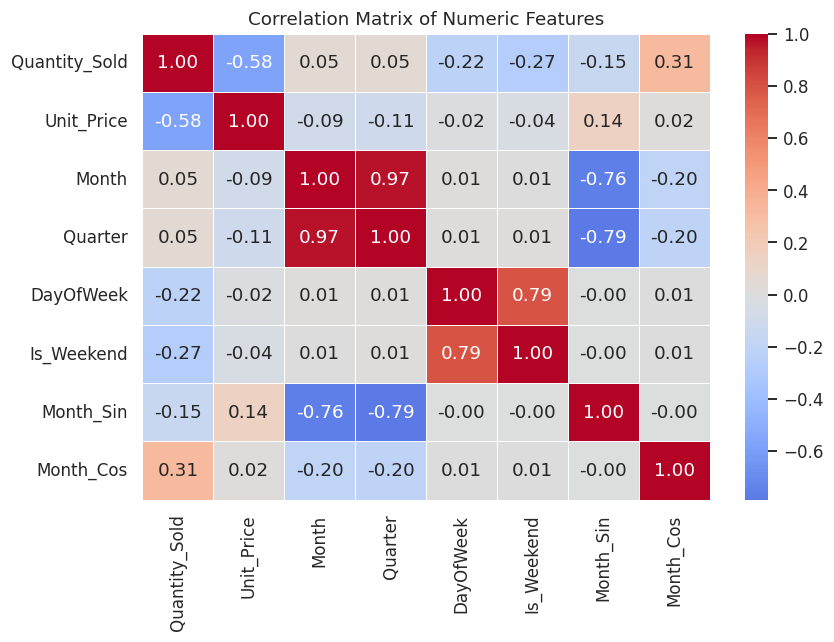

Correlation with Quantity_Sold (strongest first):


Unit_Price   -0.576
Month_Cos     0.315
Is_Weekend   -0.266
DayOfWeek    -0.223
Month_Sin    -0.146
Month         0.050
Quarter       0.049
Name: Quantity_Sold, dtype: float64

In [12]:
corr_cols = ['Quantity_Sold', 'Unit_Price', 'Month', 'Quarter', 'DayOfWeek', 'Is_Weekend', 'Month_Sin', 'Month_Cos']
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', center=0, linewidths=0.5, ax=ax)
ax.grid(False)
ax.set_title('Correlation Matrix of Numeric Features')
plt.tight_layout()
plt.show()

print('Correlation with Quantity_Sold (strongest first):')
corr['Quantity_Sold'].drop('Quantity_Sold').sort_values(key=abs, ascending=False).round(3)

### 2.2 Time-based train / test split

Sales are a time series, so the data is **not shuffled**: the model learns from the first 80% of the year (Jan to Oct) and is tested on the final 20% (Oct to Dec), exactly the situation in real life, where we forecast the future from the past.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print(f'Train: {len(X_train)} days ({df.loc[X_train.index, "Date"].min().date()} to {df.loc[X_train.index, "Date"].max().date()})')
print(f'Test : {len(X_test)} days ({df.loc[X_test.index, "Date"].min().date()} to {df.loc[X_test.index, "Date"].max().date()})')

Train: 292 days (2023-01-01 to 2023-10-19)
Test : 73 days (2023-10-20 to 2023-12-31)


### 2.3 Preprocessing pipeline

- `Drug_ID`, `Category` -> one-hot encoding (label encoding would imply a false order such as `Drug_A < Drug_B`)
- Calendar features -> passed through unchanged
- `Unit_Price` -> `MinMaxScaler` (fitted on the training data only, so nothing leaks from the test period)

The preprocessing is bundled with each model in one `Pipeline`, so the saved model accepts raw input.

In [14]:
preprocessor = ColumnTransformer([
    ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('calendar', 'passthrough', calendar_features),
    ('price', MinMaxScaler(), price_features),
])

# Verification: look at the processed training features
processed = pd.DataFrame(preprocessor.fit(X_train).transform(X_train),
                         columns=[n.split('__', 1)[1] for n in preprocessor.get_feature_names_out()])
print('Processed training matrix:', processed.shape)
processed.head()

Processed training matrix: (292, 15)


,Drug_ID_Drug_A,Drug_ID_Drug_B,Drug_ID_Drug_C,Drug_ID_Drug_D,Category_Analgesics,Category_Antibiotics,Category_Antivirals,Category_Cardiology,Month,DayOfWeek,Is_Weekend,Quarter,Month_Sin,Month_Cos,Unit_Price
0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,6.0,1.0,1.0,0.0,1.0,0.379442
1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.961066
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.904580
3,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,2.0,0.0,1.0,0.0,1.0,0.187012
4,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,3.0,0.0,1.0,0.0,1.0,0.059159


## 3. Model training

Three models are compared:

1. **Naive baseline** - always predicts the average training quantity. Any useful model must beat this.
2. **Linear Regression** - simple, fast and interpretable.
3. **Random Forest Regressor** - an ensemble of trees that can capture non-linear patterns and interactions (for example *winter x Antibiotics*). Hyper-parameters are tuned with grid search using **time-series cross-validation** (each validation fold lies after its training fold).

In [15]:
tscv = TimeSeriesSplit(n_splits=5)

baseline = Pipeline([('preprocess', preprocessor), ('model', DummyRegressor(strategy='mean'))])
baseline.fit(X_train, y_train)

lin_reg = Pipeline([('preprocess', preprocessor), ('model', LinearRegression())])
lin_reg.fit(X_train, y_train)
print('Baseline and Linear Regression trained.')

Baseline and Linear Regression trained.


In [16]:
rf_pipe = Pipeline([('preprocess', preprocessor),
                    ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))])
param_grid = {
    'model__n_estimators': [100, 300],
    'model__max_depth': [4, 8, None],
    'model__min_samples_leaf': [1, 3],
}
rf_search = GridSearchCV(rf_pipe, param_grid, scoring='neg_mean_absolute_error', cv=tscv, n_jobs=-1)
rf_search.fit(X_train, y_train)
random_forest = rf_search.best_estimator_

print('Best parameters      :', rf_search.best_params_)
print(f'Best CV MAE (units)  : {-rf_search.best_score_:.3f}')

grid_results = (pd.DataFrame(rf_search.cv_results_)
                .loc[:, ['param_model__n_estimators', 'param_model__max_depth',
                         'param_model__min_samples_leaf', 'mean_test_score', 'std_test_score']]
                .rename(columns=lambda c: c.replace('param_model__', ''))
                .assign(mean_test_score=lambda d: -d['mean_test_score'])
                .rename(columns={'mean_test_score': 'CV MAE', 'std_test_score': 'std'})
                .sort_values('CV MAE').round(3))
grid_results

Best parameters      : {'model__max_depth': 8, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
Best CV MAE (units)  : 8.262


,n_estimators,max_depth,min_samples_leaf,CV MAE,std
5,300,8,1,8.262,1.529
9,300,None,1,8.264,1.495
8,100,None,1,8.308,1.521
4,100,8,1,8.319,1.541
6,100,8,3,8.435,1.659
10,100,None,3,8.437,1.656
7,300,8,3,8.442,1.705
11,300,None,3,8.443,1.710
1,300,4,1,8.618,1.588
0,100,4,1,8.635,1.590


## 4. Model evaluation

Metrics on the **test period** (the last 20% of days, never seen during training):

- **MAE** - average error in units per day (easy to interpret)
- **RMSE** - like MAE but punishes large errors more
- **R-squared** - share of the variation in sales explained by the model (0 = no better than the average, 1 = perfect)
- **MAPE** - average error as a percentage of the real quantity

In [17]:
models = {'Naive baseline (mean)': baseline, 'Linear Regression': lin_reg, 'Random Forest (tuned)': random_forest}
y_pred, rows = {}, []

for name, model in models.items():
    y_pred[name] = model.predict(X_test)
    p = y_pred[name]
    cv_mae = -cross_val_score(model, X_train, y_train, cv=tscv, scoring='neg_mean_absolute_error').mean()
    rows.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, p),
        'RMSE': np.sqrt(mean_squared_error(y_test, p)),
        'R2': r2_score(y_test, p),
        'MAPE (%)': np.mean(np.abs((y_test - p) / y_test)) * 100,
        'Train R2': r2_score(y_train, model.predict(X_train)),
        'CV MAE': cv_mae,
    })

results = pd.DataFrame(rows).set_index('Model').round(3)
results

,MAE,RMSE,R2,MAPE (%),Train R2,CV MAE
Model,,,,,,
Naive baseline (mean),11.602,13.847,-0.319,23.903,0.000,11.112
Linear Regression,6.683,8.483,0.505,13.388,0.697,7.458
Random Forest (tuned),7.667,9.695,0.354,15.281,0.933,8.262


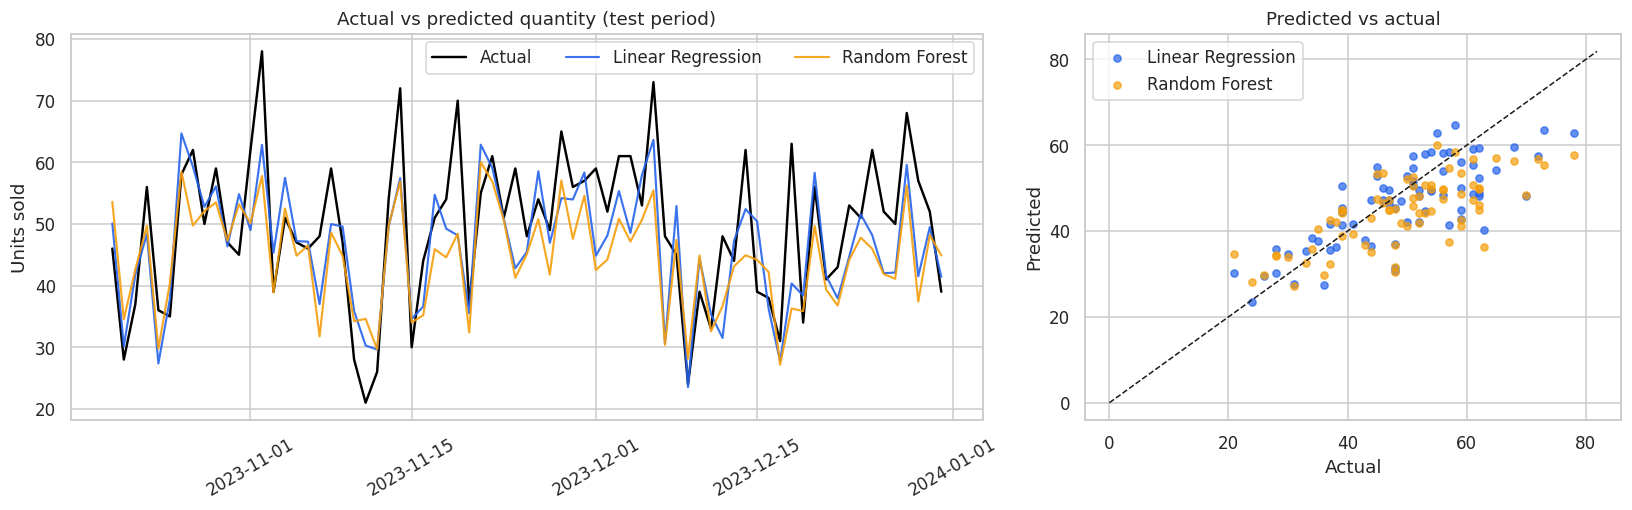

In [18]:
test_dates = df.loc[X_test.index, 'Date']

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1.7, 1]})

# Actual vs predicted over time
axes[0].plot(test_dates, y_test.values, color='black', lw=1.6, label='Actual')
axes[0].plot(test_dates, y_pred['Linear Regression'], color=BLUE, lw=1.4, alpha=0.9, label='Linear Regression')
axes[0].plot(test_dates, y_pred['Random Forest (tuned)'], color=AMBER, lw=1.4, alpha=0.9, label='Random Forest')
axes[0].set_title('Actual vs predicted quantity (test period)')
axes[0].set_ylabel('Units sold')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend(ncol=3)

# Predicted vs actual scatter
lim = [min(y_test.min(), 0), y_test.max() * 1.05]
axes[1].plot(lim, lim, 'k--', lw=1)
axes[1].scatter(y_test, y_pred['Linear Regression'], s=22, alpha=0.7, color=BLUE, label='Linear Regression')
axes[1].scatter(y_test, y_pred['Random Forest (tuned)'], s=22, alpha=0.7, color=AMBER, label='Random Forest')
axes[1].set_xlabel('Actual')
axes[1].set_ylabel('Predicted')
axes[1].set_title('Predicted vs actual')
axes[1].legend()

plt.tight_layout()
plt.show()

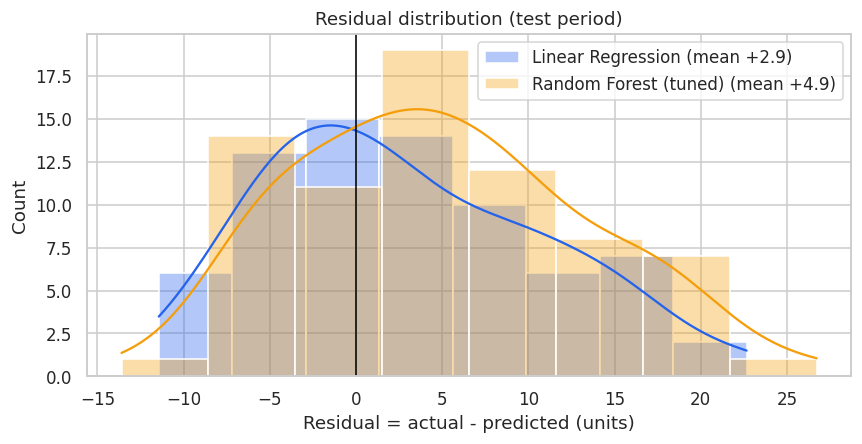

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for (name, color) in [('Linear Regression', BLUE), ('Random Forest (tuned)', AMBER)]:
    residuals = y_test.values - y_pred[name]
    sns.histplot(residuals, kde=True, color=color, alpha=0.35, label=f'{name} (mean {residuals.mean():+.1f})', ax=ax)
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('Residual = actual - predicted (units)')
ax.set_title('Residual distribution (test period)')
ax.legend()
plt.tight_layout()
plt.show()

## 5. What drives demand?

We use **permutation importance** on the test period: each original feature is shuffled in turn, and we measure how much the model's R-squared drops. A large drop means the model relies heavily on that feature. This works on the original columns (so `Category` is one bar, not four).

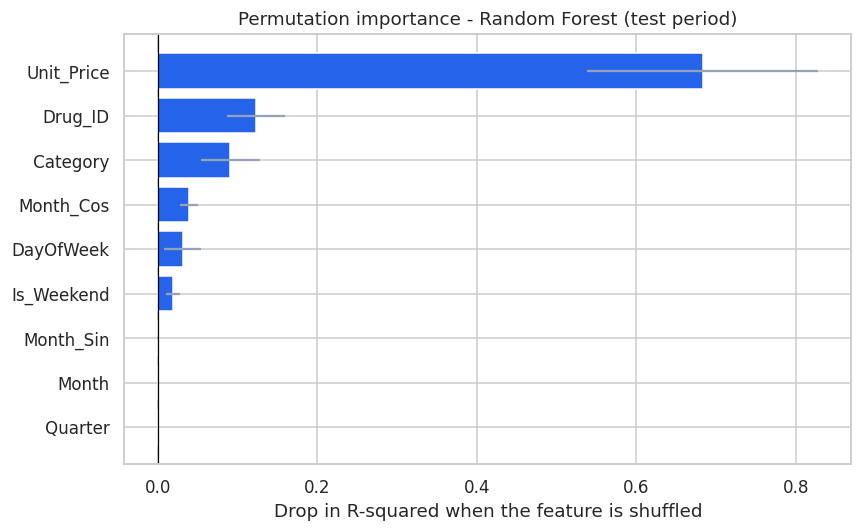

,Importance
Unit_Price,0.683
Drug_ID,0.123
Category,0.091
Month_Cos,0.039
DayOfWeek,0.031
Is_Weekend,0.019
Month_Sin,0.001
Month,0.000
Quarter,0.000


In [20]:
perm = permutation_importance(random_forest, X_test, y_test, scoring='r2', n_repeats=30,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_importance = (pd.Series(perm.importances_mean, index=X_test.columns)
                   .sort_values(ascending=False))
perm_std = pd.Series(perm.importances_std, index=X_test.columns).loc[perm_importance.index]

top = perm_importance.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, xerr=perm_std.loc[top.index].values, color=BLUE, ecolor='#94a3b8')
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Drop in R-squared when the feature is shuffled')
ax.set_title('Permutation importance - Random Forest (test period)')
plt.tight_layout()
plt.show()

perm_importance.round(3).to_frame('Importance')

### 5.1 Linear Regression coefficients (effect in units)

Coefficients tell us the average change in daily units for each feature, holding the others constant. Price is scaled 0-1, so its coefficient is the change from the cheapest to the most expensive price.

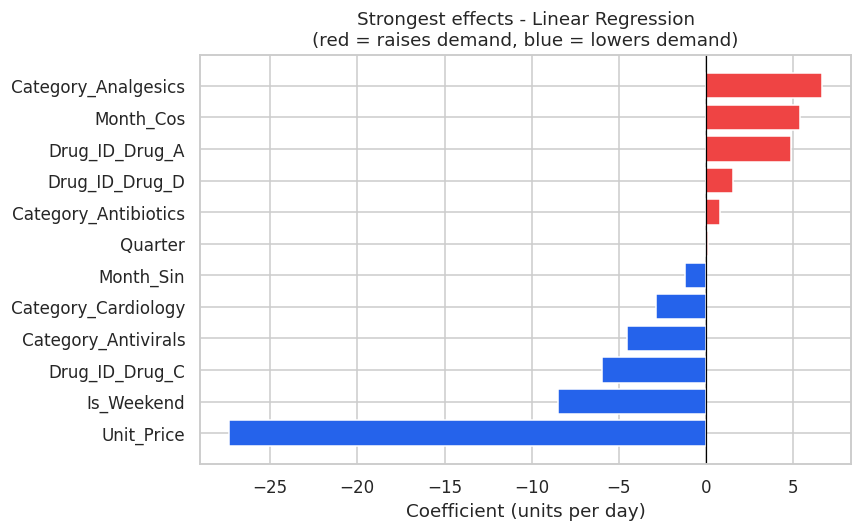

In [21]:
lin_names = [n.split('__', 1)[1] for n in lin_reg.named_steps['preprocess'].get_feature_names_out()]
lin_coefs = pd.Series(lin_reg.named_steps['model'].coef_, index=lin_names).sort_values()

top = pd.concat([lin_coefs.head(6), lin_coefs.tail(6)]).drop_duplicates()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=[RED if v > 0 else BLUE for v in top.values])
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Coefficient (units per day)')
ax.set_title('Strongest effects - Linear Regression\n(red = raises demand, blue = lowers demand)')
plt.tight_layout()
plt.show()

## 6. Demand-planning view

A forecasting model is only useful if it supports a decision. Below, the Random Forest predicts the **average daily demand** for every category in every month (weekday sale, median price, averaged over the four drugs). Pharmacy managers can use such a table to decide how much stock to order for each season.

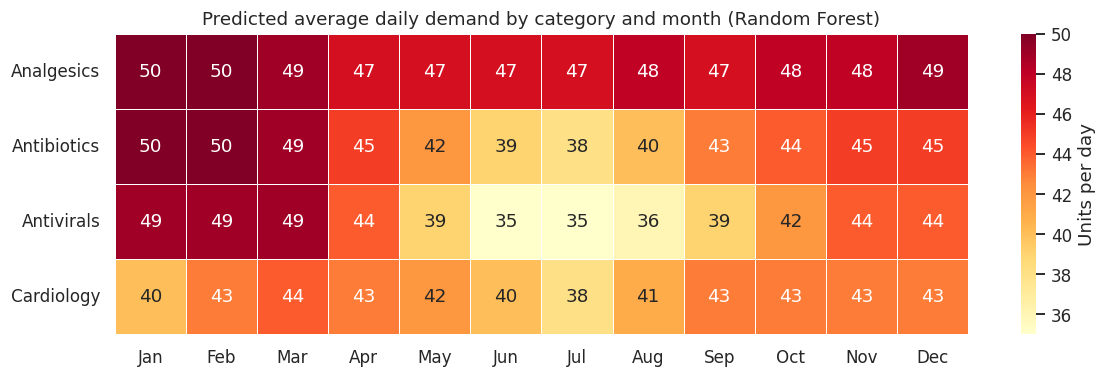

In [22]:
months = list(range(1, 13))
plan_rows = []
for cat in sorted(df['Category'].unique()):
    for m in months:
        for drug in sorted(df['Drug_ID'].unique()):
            plan_rows.append({'Drug_ID': drug, 'Category': cat, 'Month': m, 'DayOfWeek': 2, 'Is_Weekend': 0,
                              'Quarter': (m - 1) // 3 + 1,
                              'Month_Sin': np.sin(2 * np.pi * (m - 1) / 12), 'Month_Cos': np.cos(2 * np.pi * (m - 1) / 12),
                              'Unit_Price': df['Unit_Price'].median()})
plan = pd.DataFrame(plan_rows)
plan['Predicted'] = random_forest.predict(plan[features])
plan_table = plan.groupby(['Category', 'Month'])['Predicted'].mean().unstack().round(0)
plan_table.columns = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(plan_table, annot=True, fmt='.0f', cmap='YlOrRd', linewidths=0.5, cbar_kws={'label': 'Units per day'}, ax=ax)
ax.grid(False)
ax.set_ylabel('')
ax.set_title('Predicted average daily demand by category and month (Random Forest)')
plt.tight_layout()
plt.show()

## 7. Saving the models and predicting for new scenarios

Both trained pipelines (preprocessing + model) are saved as `.pkl` files so they can be reused without retraining.

> The pickles depend on the scikit-learn version they were created with (shown in the setup cell). If you load them with a very different version and see an error, simply re-run this notebook to regenerate them.

In [23]:
with open('linear_regression_model.pkl', 'wb') as f:
    pickle.dump(lin_reg, f)
with open('random_forest_model.pkl', 'wb') as f:
    pickle.dump(random_forest, f)

# Reload and verify that the predictions are identical
with open('linear_regression_model.pkl', 'rb') as f:
    lin_loaded = pickle.load(f)
with open('random_forest_model.pkl', 'rb') as f:
    rf_loaded = pickle.load(f)

assert np.allclose(lin_loaded.predict(X_test), lin_reg.predict(X_test))
assert np.allclose(rf_loaded.predict(X_test), random_forest.predict(X_test))

for fname in ['linear_regression_model.pkl', 'random_forest_model.pkl']:
    print(f'{fname:<30} {os.path.getsize(fname) / 1024:,.0f} KB')
print('Models saved, reloaded and verified.')

linear_regression_model.pkl    3 KB
random_forest_model.pkl        4,862 KB
Models saved, reloaded and verified.


In [24]:
def make_scenario(date, drug, category, price):
    """Build one raw input row from a date, a drug, a category and a unit price."""
    d = pd.Timestamp(date)
    return {'Drug_ID': drug, 'Category': category, 'Month': d.month, 'DayOfWeek': d.dayofweek,
            'Is_Weekend': int(d.dayofweek >= 5), 'Quarter': d.quarter,
            'Month_Sin': np.sin(2 * np.pi * (d.month - 1) / 12), 'Month_Cos': np.cos(2 * np.pi * (d.month - 1) / 12),
            'Unit_Price': price}


scenarios = pd.DataFrame([
    ('2024-01-16', 'Drug_A', 'Antibiotics', 40.0),   # winter weekday, cheap
    ('2024-07-14', 'Drug_A', 'Antibiotics', 40.0),   # summer Sunday, cheap
    ('2024-01-16', 'Drug_C', 'Antivirals', 140.0),   # winter weekday, expensive
    ('2024-03-05', 'Drug_B', 'Analgesics', 60.0),    # spring weekday
], columns=['Date', 'Drug_ID', 'Category', 'Unit_Price'])

new_X = pd.DataFrame([make_scenario(r.Date, r.Drug_ID, r.Category, r.Unit_Price) for r in scenarios.itertuples()])[features]
out = scenarios.assign(Linear_Regression=lin_loaded.predict(new_X).round(1),
                       Random_Forest=rf_loaded.predict(new_X).round(1))
out

,Date,Drug_ID,Category,Unit_Price,Linear_Regression,Random_Forest
0,2024-01-16,Drug_A,Antibiotics,40.0,66.4,65.7
1,2024-07-14,Drug_A,Antibiotics,40.0,45.4,43.9
2,2024-01-16,Drug_C,Antivirals,140.0,30.4,38.4
3,2024-03-05,Drug_B,Analgesics,60.0,58.5,57.8


## 8. Conclusion

**Results on the test period (73 days)**

| Model | MAE (units) | RMSE (units) | R-squared | MAPE (%) |
|-------|------------:|-------------:|----------:|---------:|
| Naive baseline (mean) | 11.60 | 13.85 | -0.319 | 23.9 |
| Linear Regression | 6.68 | 8.48 | 0.505 | 13.4 |
| Random Forest (tuned) | 7.67 | 9.70 | 0.354 | 15.3 |

**Key findings**

- Both models beat the naive baseline. **Linear Regression** is the best model (R-squared 0.505) and cuts the average error by about 42% compared with predicting the average. The baseline's negative R-squared suggests that the Oct-Dec period differs from the average of the earlier months, i.e. seasonality matters.
- The Random Forest fits the training days very closely (train R-squared 0.93) but generalises worse (test R-squared 0.35). With only 292 training days, and effects that are mostly additive (price, weekend, drug and category offsets), the simpler model is the better choice here. The Random Forest may catch up with more data.
- The most important factors in the Random Forest are `Unit_Price`, `Drug_ID`, `Category`; `Unit_Price` dominates.
- Antibiotics and Antivirals show a strong winter peak; weekends sell less; higher prices reduce demand.
- The demand-planning table (Section 6) turns the model into a practical tool for deciding how much stock to order per category and season.

**Limitations**

- The data is synthetic and covers a single year, so seasonality cannot be validated over several years and the absolute scores should not be quoted as real-world performance.
- In this dataset each day has only one sale record, with `Drug_ID` and `Category` assigned independently. Real pharmacy data would have one row per drug per day, with each drug belonging to one category.
- No holidays, promotions, stock-outs or epidemic information is included.

**Future work:** use several years of real sales data, add holiday / promotion / weather features, try gradient boosting and dedicated time-series models (SARIMA, Prophet), and produce forecast intervals instead of single numbers.